# Mercado de Dados no Brasil: análise exploratória da pesquisa State of Data 2025–2026

Projeto de Ciência de Dados desenvolvido com Python, Pandas, Matplotlib e Seaborn.

## Objetivo

Investigar o perfil dos participantes da pesquisa e explorar como as respostas se distribuem em temas como formação, experiência, remuneração, modelos de trabalho e tecnologias utilizadas.

## Perguntas que vamos investigar

1. Qual é o perfil dos participantes que responderam à pesquisa?
2. Como as faixas salariais se distribuem entre os níveis profissionais?
3. Como os modelos de trabalho atuais se comparam aos modelos desejados?
4. Quais linguagens de programação aparecem entre as preferências dos participantes?
5. Quais limitações precisamos considerar antes de interpretar os resultados?

## Cuidados importantes

Esta é uma análise descritiva das respostas disponíveis no arquivo. Os resultados descrevem os participantes da pesquisa e não devem ser tratados automaticamente como uma representação de todos os profissionais de dados do Brasil. Associações observadas não demonstram causa e efeito.

O arquivo contém uma coluna de token de resposta. Ela não será utilizada na análise nem exibida nos resultados.

In [1]:
from pathlib import Path
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# Define um padrão visual simples para os gráficos.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Procura o arquivo na pasta data ou na mesma pasta em que o notebook estiver.
nome_arquivo = "Final Dataset - State of Data 2025-2026 - Kaggle.csv"
caminhos_possiveis = [
    Path("../data") / nome_arquivo,
    Path("data") / nome_arquivo,
    Path(nome_arquivo),
    Path("../../data") / nome_arquivo,
]

caminho_arquivo = next((caminho for caminho in caminhos_possiveis if caminho.exists()), None)

if caminho_arquivo is None:
    raise FileNotFoundError(
        "Não encontrei o CSV. Coloque o arquivo na pasta data do projeto "
        "ou na mesma pasta do notebook."
    )

# low_memory=False ajuda o Pandas a interpretar o arquivo de maneira mais consistente.
df_original = pd.read_csv(caminho_arquivo, low_memory=False)

# Mantém uma cópia para trabalhar sem alterar a leitura original.
df = df_original.copy()

print(f"Arquivo carregado: {caminho_arquivo}")
print(f"Quantidade de respostas: {df.shape[0]:,}")
print(f"Quantidade de colunas: {df.shape[1]:,}")

Arquivo carregado: ..\data\Final Dataset - State of Data 2025-2026 - Kaggle.csv
Quantidade de respostas: 3,495
Quantidade de colunas: 388


## 2. Conhecer a estrutura dos dados

Nesta etapa verificamos o tamanho da tabela, os nomes das colunas e alguns registros. Isso ajuda a entender como a pesquisa foi organizada antes de escolher as análises.

In [2]:
# Exibe as primeiras linhas sem mostrar a coluna que identifica o token da resposta.
colunas_visiveis = [coluna for coluna in df.columns if "token" not in coluna.lower()]
display(df[colunas_visiveis].head(5))

# Lista os nomes das colunas para consulta.
for numero, coluna in enumerate(df.columns, start=1):
    if "token" not in coluna.lower():
        print(f"{numero}. {coluna}")

,0.d_data/hora_envio,1.a_idade,1.a.1_faixa_idade,1.b_genero,1.c_cor/raca/etnia,1.d_pcd,1.e_experiencia_profissional_prejudicada,1.e.1_Não acredito que minha experiência profissional seja afetada,"1.e.2_Sim, devido a minha Cor/Raça/Etnia","1.e.3_Sim, devido a minha identidade de gênero",...,8.d.4_Desenvolvendo modelos de Machine Learning com o objetivo de colocar em produção em sistemas (produtos de dados).,"8.d.5_Colocando modelos em produção, criando os pipelines de dados, APIs de consumo e monitoramento.","8.d.6_Cuidando da manutenção de modelos de Machine Learning já em produção, atuando no monitoramento, ajustes e refatoração quando necessário.","8.d.7_Realizando construções de dashboards em ferramentas de BI como PowerBI, Tableau, Looker, Qlik, etc.","8.d.8_Utilizando ferramentas avançadas de estatística como SAS, SPSS, Stata etc, para realizar análises.","8.d.9_Criando e dando manutenção em ETLs, DAGs e automações de pipelines de dados.",8.d.10_Criando e gerenciando soluções de Feature Store e cultura de MLOps.,"8.d.11_Criando e mantendo a infra que meus modelos e soluções rodam (clusters, servidores, API, containers, etc.)",8.d.12_Treinando e aplicando LLM's para solucionar problemas de negócio.,8.d_maior_tempo_gasto_como_ds
0,20/10/2025 10:20:11,35,35-39,Masculino,Branca,Não,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,20/10/2025 10:27:09,20,17-21,Masculino,Branca,Não,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,20/10/2025 10:28:59,35,35-39,Masculino,Branca,Não,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,20/10/2025 10:30:24,29,25-29,Masculino,Parda,Não,Não acredito que minha experiência profissiona...,1.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,20/10/2025 10:33:11,18,17-21,Masculino,Preta,Não,Não acredito que minha experiência profissiona...,1.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


2. 0.d_data/hora_envio
3. 1.a_idade
4. 1.a.1_faixa_idade
5. 1.b_genero
6. 1.c_cor/raca/etnia
7. 1.d_pcd
8. 1.e_experiencia_profissional_prejudicada
9. 1.e.1_Não acredito que minha experiência profissional seja afetada
10. 1.e.2_Sim, devido a minha Cor/Raça/Etnia
11. 1.e.3_Sim, devido a minha identidade de gênero
12. 1.e.4_Sim, devido ao fato de ser PCD
13. 1.f_aspectos_prejudicados
14. 1.f.1_Quantidade de oportunidades de emprego/vagas recebidas
15. 1.f.2_Senioridade das vagas recebidas em relação à sua experiência
16. 1.f.3_Aprovação em processos seletivos/entrevistas
17. 1.f.4_Oportunidades de progressão de carreira
18. 1.f.5_Velocidade de progressão de carreira
19. 1.f.6_Nível de cobrança no trabalho/Stress no trabalho
20. 1.f.7_Atenção dada pelas pessoas diante das minhas opiniões e ideias
21. 1.f.8_Relação com outras pessoas da empresa, em momentos de trabalho
22. 1.f.9_Relação com outras pessoas da empresa, em momentos de integração e outros momentos fora do trabalho
23. 1.g_vive

## 3. Avaliar a qualidade dos dados

Valores ausentes não são necessariamente erros: algumas perguntas podem ser exibidas apenas para determinados grupos. Por isso, vamos medir os valores ausentes e duplicados, mas não vamos excluir linhas automaticamente.

,tipo_de_dado,valores_preenchidos,valores_ausentes,percentual_ausente
1.h_pais_onde_mora,object,122,3373,96.51
5.b_oportunidade_buscada,object,183,3312,94.76
5.d_experiencia_em_processos_seletivos,object,187,3308,94.65
5.c_tempo_em_busca_de_oportunidade,object,192,3303,94.51
5.a_objetivo_na_area_de_dados,object,414,3081,88.15
6.d_tecnologia_data_lake,object,415,3080,88.13
6.f_tecnologia_data_warehouse,object,420,3075,87.98
"8.c.3_Ambientes de desenvolvimento local (R-studio, JupyterLab, Anaconda).",float64,490,3005,85.98
"8.c.4_Ambientes de desenvolvimento na nuvem (Google Colab, AWS Sagemaker, Kaggle Notebooks etc).",float64,490,3005,85.98
"8.c.2_Planilhas (Excel, Google Sheets etc).",float64,490,3005,85.98


Linhas totalmente duplicadas: 1


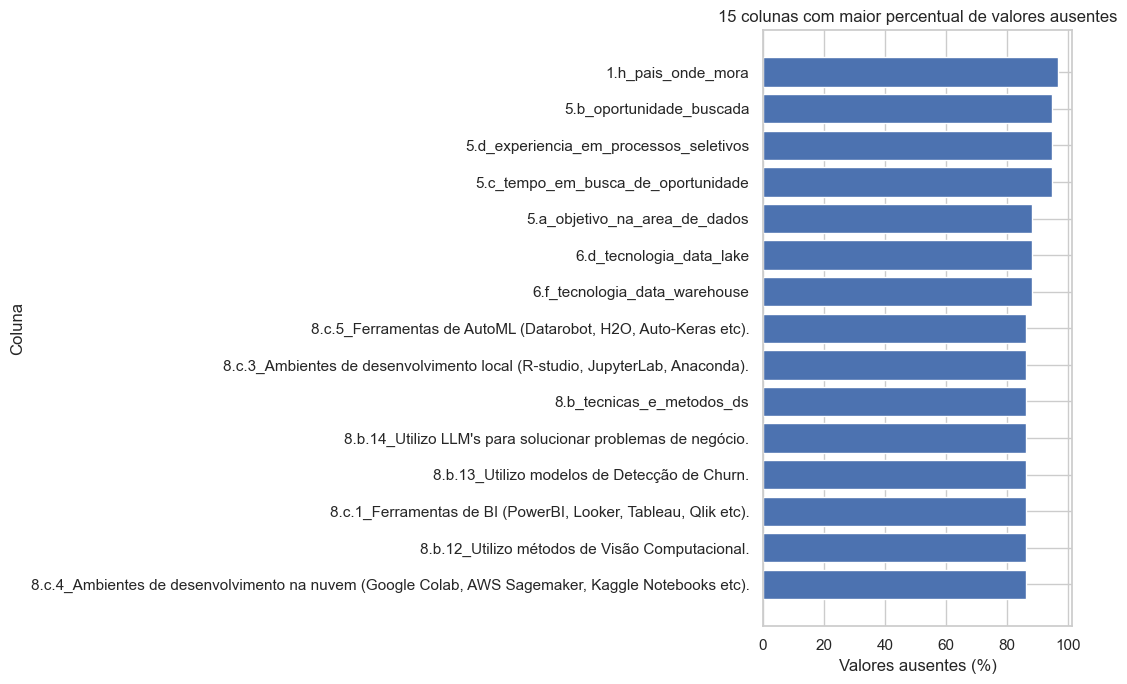

In [3]:
# Resumo dos tipos de dados e da quantidade de valores preenchidos.
resumo_estrutura = pd.DataFrame({
    "tipo_de_dado": df.dtypes.astype(str),
    "valores_preenchidos": df.notna().sum(),
    "valores_ausentes": df.isna().sum(),
    "percentual_ausente": (df.isna().mean() * 100).round(2)
})

display(resumo_estrutura.sort_values("percentual_ausente", ascending=False).head(25))

# Conta linhas totalmente duplicadas e duplicatas considerando todas as colunas.
print("Linhas totalmente duplicadas:", df.duplicated().sum())

# Percentual de respostas ausentes por coluna, excluindo a coluna de token.
resumo_ausencias = resumo_estrutura.drop(
    index=[coluna for coluna in resumo_estrutura.index if "token" in coluna.lower()],
    errors="ignore"
).sort_values("percentual_ausente", ascending=False)

# Usa o gráfico horizontal do próprio Pandas para manter a visualização simples e compatível.
dados_grafico_ausencias = resumo_ausencias.head(15).sort_values("percentual_ausente")
plt.figure(figsize=(11, 7))
plt.barh(dados_grafico_ausencias.index.astype(str), dados_grafico_ausencias["percentual_ausente"])
plt.title("15 colunas com maior percentual de valores ausentes")
plt.xlabel("Valores ausentes (%)")
plt.ylabel("Coluna")
plt.tight_layout()
plt.show()

## 4. Criar funções auxiliares

As funções abaixo facilitam a análise e evitam repetir o mesmo código. Elas também verificam se a coluna desejada existe no arquivo.

In [4]:
def verificar_coluna(nome_coluna):
    """Confirma se a coluna existe antes de usá-la."""
    if nome_coluna not in df.columns:
        print(f"A coluna '{nome_coluna}' não foi encontrada. Confira os nomes na seção 2.")
        return False
    return True


def mostrar_frequencias(nome_coluna, titulo, limite=15):
    """Mostra contagens e percentuais de uma coluna categórica."""
    if not verificar_coluna(nome_coluna):
        return None

    dados = df[nome_coluna].dropna().astype(str).str.strip()
    dados = dados[dados.ne("")]

    if dados.empty:
        print(f"Não há respostas preenchidas para '{nome_coluna}'.")
        return None

    tabela = dados.value_counts().head(limite).rename_axis("categoria").reset_index(name="quantidade")
    total_preenchido = dados.shape[0]
    tabela["percentual_das_respostas_preenchidas"] = (
        tabela["quantidade"] / total_preenchido * 100
    ).round(2)

    display(tabela)

    # O gráfico horizontal facilita a leitura dos nomes das categorias.
    tabela_grafico = tabela.sort_values("quantidade")
    plt.figure(figsize=(11, max(5, len(tabela_grafico) * 0.4)))
    plt.barh(tabela_grafico["categoria"], tabela_grafico["quantidade"])
    plt.title(titulo)
    plt.xlabel("Número de respostas")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    return tabela

## 5. Perfil dos participantes

Vamos começar por características gerais. Os percentuais apresentados em cada tabela usam como base as respostas preenchidas daquela pergunta, e não necessariamente o total de linhas do arquivo.

Análise: Distribuição das faixas etárias


,categoria,quantidade,percentual_das_respostas_preenchidas
0,30-34,961,27.50
1,25-29,834,23.86
2,35-39,649,18.57
3,40-44,318,9.10
4,22-24,240,6.87
5,45-49,196,5.61
6,17-21,108,3.09
7,50-54,96,2.75
8,55+,93,2.66


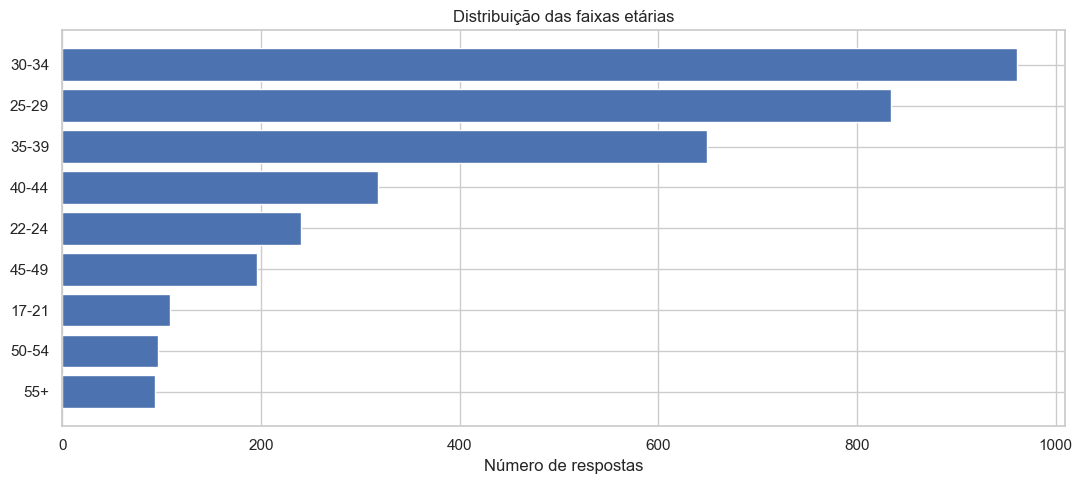

Análise: Distribuição por gênero


,categoria,quantidade,percentual_das_respostas_preenchidas
0,Masculino,2707,77.45
1,Feminino,768,21.97
2,Prefiro não informar,13,0.37
3,Outro,7,0.20


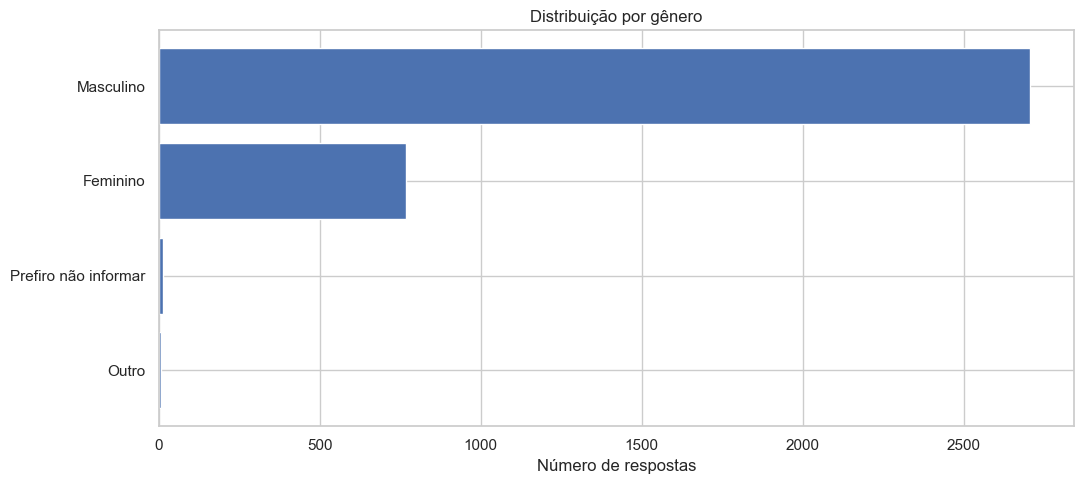

Análise: Distribuição por região de residência


,categoria,quantidade,percentual_das_respostas_preenchidas
0,Sudeste,2171,64.42
1,Sul,540,16.02
2,Nordeste,380,11.28
3,Centro-oeste,231,6.85
4,Norte,48,1.42


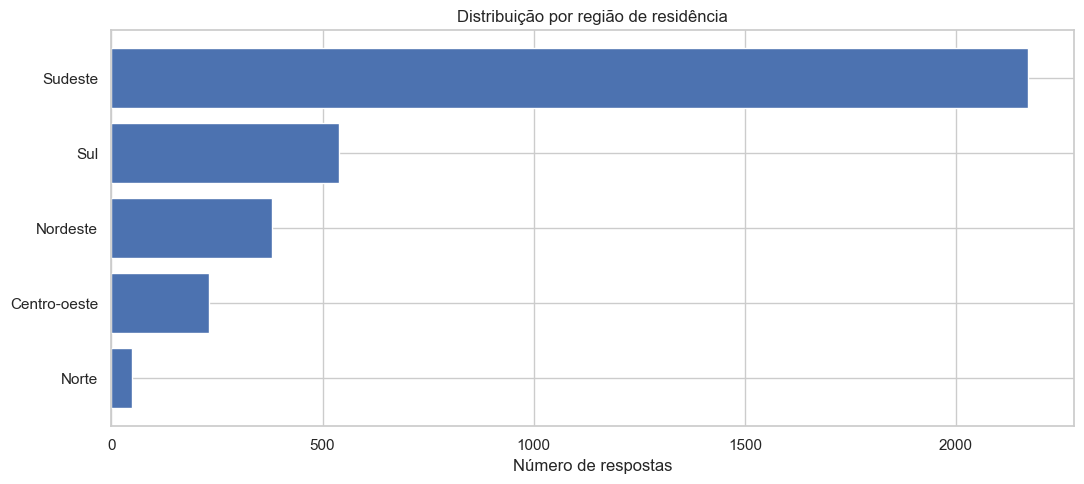

Análise: Distribuição por nível de ensino


,categoria,quantidade,percentual_das_respostas_preenchidas
0,Pós-graduação,1404,40.17
1,Graduação/Bacharelado,1068,30.56
2,Mestrado,444,12.70
3,Estudante de Graduação,355,10.16
4,Doutorado ou Phd,152,4.35
5,Não tenho graduação formal,61,1.75
6,Prefiro não informar,11,0.31


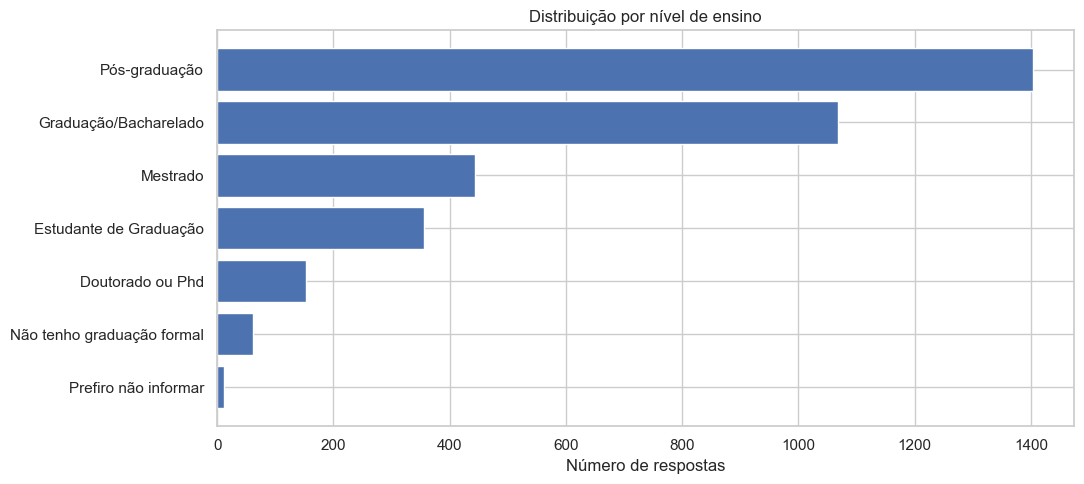

Análise: Situação de trabalho dos participantes


,categoria,quantidade,percentual_das_respostas_preenchidas
0,Empregado (CLT),2279,65.21
1,Empreendedor ou Empregado (CNPJ),428,12.25
2,"Desempregado, buscando recolocação",167,4.78
3,Vivo no Brasil e trabalho remoto para empresa ...,141,4.03
4,Estagiário,126,3.61
5,Servidor Público,123,3.52
6,Vivo fora do Brasil e trabalho para empresa de...,66,1.89
7,Trabalho na área Acadêmica/Pesquisador,44,1.26
8,Freelancer,37,1.06
9,Somente Estudante (graduação),34,0.97


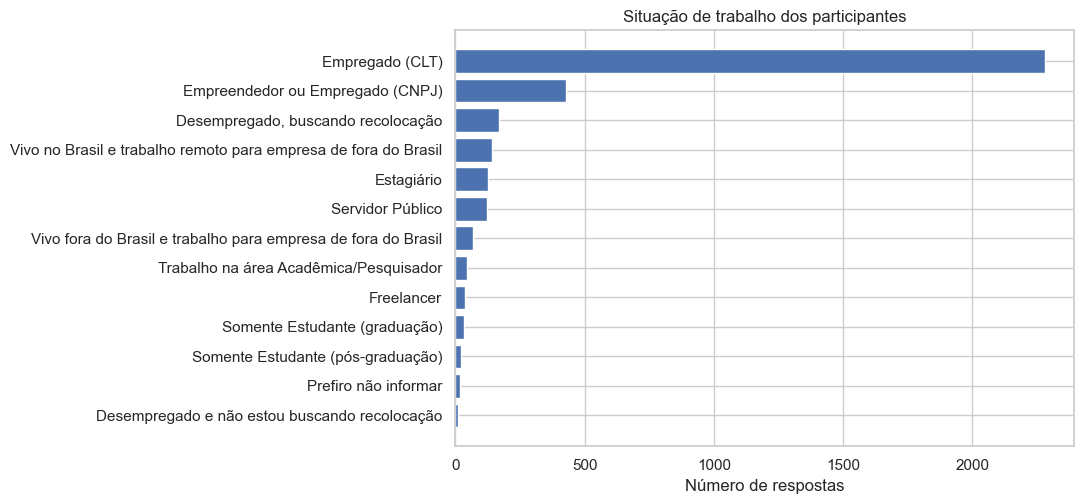

In [5]:
colunas_perfil = {
    "1.a.1_faixa_idade": "Distribuição das faixas etárias",
    "1.b_genero": "Distribuição por gênero",
    "1.i.2_regiao_onde_mora": "Distribuição por região de residência",
    "1.l_nivel_de_ensino": "Distribuição por nível de ensino",
    "2.a_situação_de_trabalho": "Situação de trabalho dos participantes",
}

tabelas_perfil = {}

for coluna, titulo in colunas_perfil.items():
    if coluna in df.columns:
        print(f"Análise: {titulo}")
        tabelas_perfil[coluna] = mostrar_frequencias(coluna, titulo)
    else:
        print(f"Coluna não encontrada nesta versão do arquivo: {coluna}")

## 6. Experiência profissional

Vamos verificar como os participantes se distribuem por tempo de experiência na área de dados. A experiência em dados e a experiência em tecnologia da informação são medidas diferentes, por isso vamos mantê-las separadas.

Análise: Tempo de experiência em dados


,categoria,quantidade,percentual_das_respostas_preenchidas
0,de 3 a 4 anos,814,25.22
1,de 5 a 6 anos,650,20.14
2,de 1 a 2 anos,511,15.83
3,Mais de 10 anos,440,13.63
4,de 7 a 10 anos,417,12.92
5,Menos de 1 ano,218,6.75
6,Não tenho experiência na área de dados,178,5.51


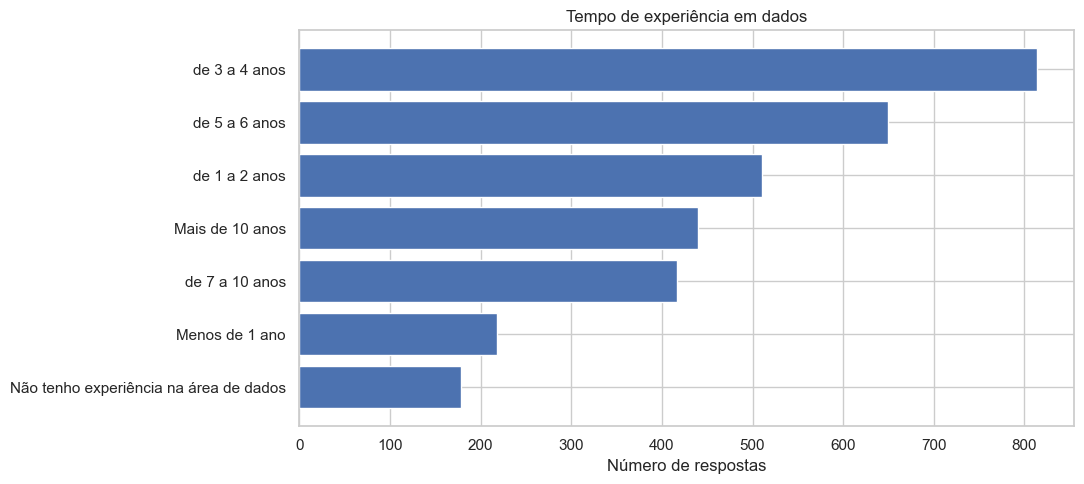

Análise: Tempo de experiência em TI


,categoria,quantidade,percentual_das_respostas_preenchidas
0,Não tive experiência na área de TI/Engenharia ...,1746,54.09
1,de 1 a 2 anos,357,11.06
2,Mais de 10 anos,322,9.98
3,Menos de 1 ano,279,8.64
4,de 3 a 4 anos,233,7.22
5,de 5 a 6 anos,167,5.17
6,de 7 a 10 anos,124,3.84


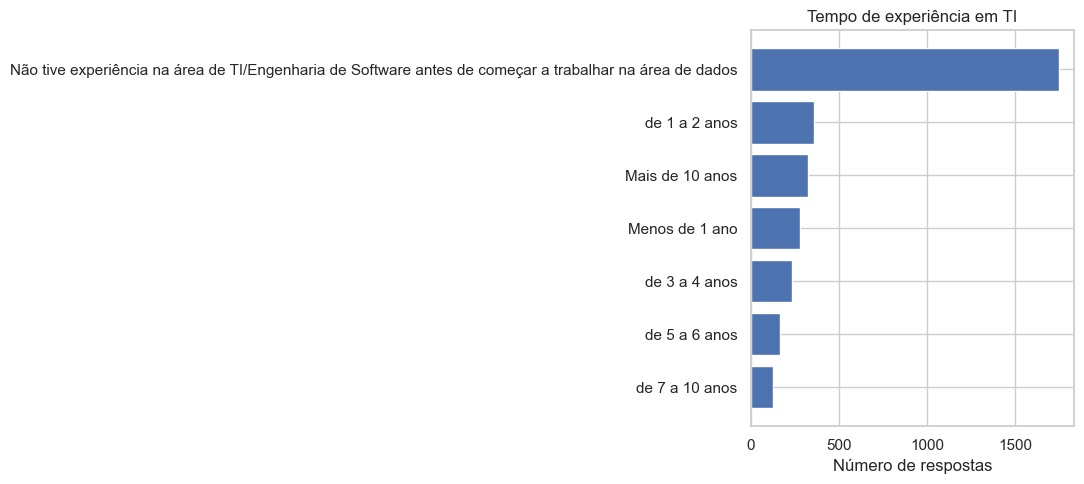

Análise: Nível profissional informado


,categoria,quantidade,percentual_das_respostas_preenchidas
0,Sênior,858,34.31
1,Pleno,776,31.03
2,Júnior,518,20.71
3,Especialista/Staff+,349,13.95


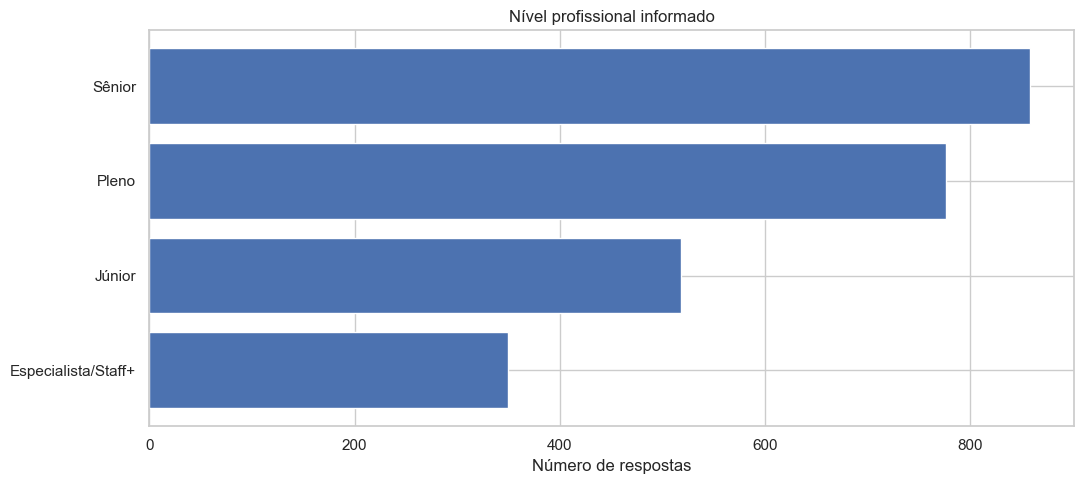

In [6]:
colunas_experiencia = {
    "2.i_tempo_de_experiencia_em_dados": "Tempo de experiência em dados",
    "2.j_tempo_de_experiencia_em_ti": "Tempo de experiência em TI",
    "2.g_nivel": "Nível profissional informado",
}

for coluna, titulo in colunas_experiencia.items():
    if coluna in df.columns:
        print(f"Análise: {titulo}")
        mostrar_frequencias(coluna, titulo)
    else:
        print(f"Coluna não encontrada: {coluna}")

## 7. Remuneração por nível profissional

A pesquisa registra a remuneração em faixas salariais. Por esse motivo, vamos comparar a quantidade de respostas em cada faixa, em vez de calcular uma média salarial exata a partir de categorias.

As linhas com remuneração ou nível ausentes serão deixadas de fora apenas desta comparação.

2.h_faixa_salarial,Acima de R$ 40.001/mês,Menos de R$ 1.000/mês,de R$ 1.001/mês a R$ 2.000/mês,de R$ 12.001/mês a R$ 16.000/mês,de R$ 16.001/mês a R$ 20.000/mês,de R$ 2.001/mês a R$ 3.000/mês,de R$ 20.001/mês a R$ 25.000/mês,de R$ 25.001/mês a R$ 30.000/mês,de R$ 3.001/mês a R$ 4.000/mês,de R$ 30.001/mês a R$ 40.000/mês,de R$ 4.001/mês a R$ 6.000/mês,de R$ 6.001/mês a R$ 8.000/mês,de R$ 8.001/mês a R$ 12.000/mês
2.g_nivel,,,,,,,,,,,,,
Especialista/Staff+,6.9,0.0,0.0,26.1,22.9,0.0,12.9,6.6,0.0,8.3,0.6,2.3,13.5
Júnior,0.0,3.3,19.3,1.4,0.0,18.9,0.2,0.0,17.0,0.0,23.6,9.1,7.3
Pleno,0.3,0.0,1.4,8.1,0.9,2.6,0.6,0.5,6.3,0.6,20.9,25.0,32.7
Sênior,3.0,0.0,0.3,23.5,13.6,0.7,5.5,3.6,1.3,2.8,4.0,9.2,32.4


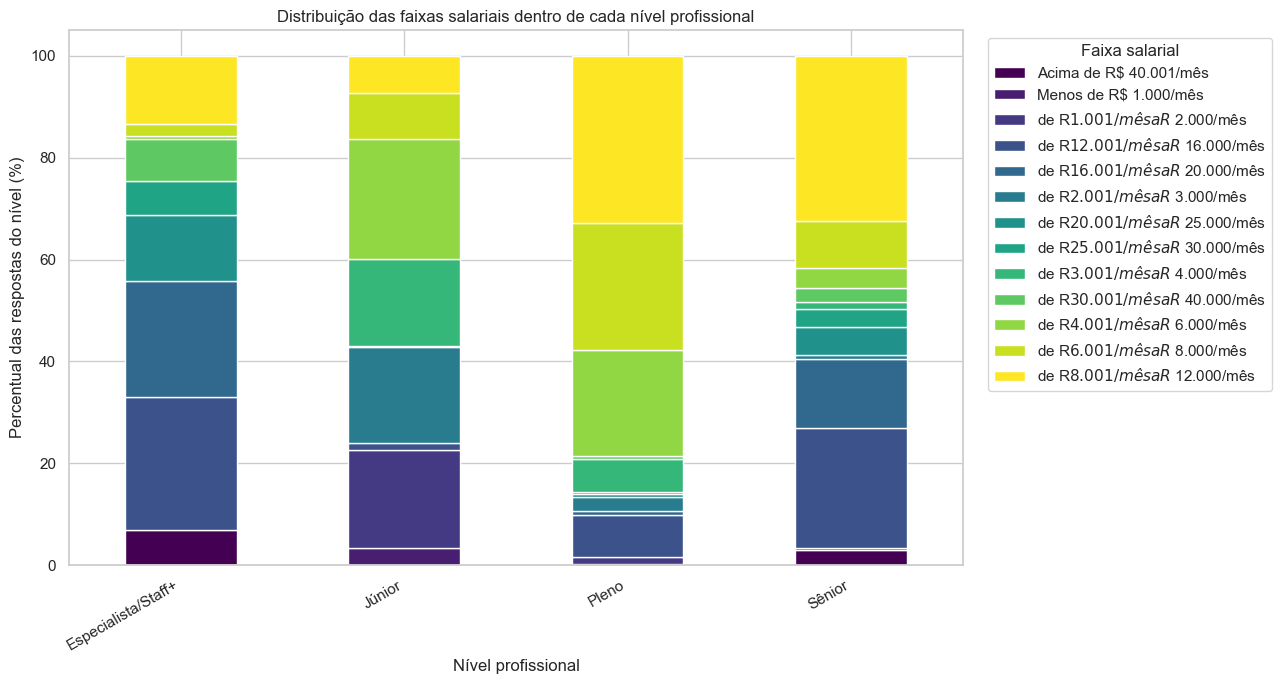

In [7]:
coluna_salario = "2.h_faixa_salarial"
coluna_nivel = "2.g_nivel"

if coluna_salario in df.columns and coluna_nivel in df.columns:
    dados_salario = df[[coluna_nivel, coluna_salario]].dropna().copy()
    dados_salario[coluna_nivel] = dados_salario[coluna_nivel].astype(str).str.strip()
    dados_salario[coluna_salario] = dados_salario[coluna_salario].astype(str).str.strip()
    dados_salario = dados_salario[
        dados_salario[coluna_nivel].ne("") & dados_salario[coluna_salario].ne("")
    ]

    if not dados_salario.empty:
        tabela_salario = pd.crosstab(
            dados_salario[coluna_nivel],
            dados_salario[coluna_salario],
            normalize="index"
        ) * 100

        # Mostra percentuais dentro de cada nível profissional.
        display(tabela_salario.round(1))

        # Gráfico empilhado: cada linha representa 100% das respostas daquele nível.
        ax = tabela_salario.plot(kind="bar", stacked=True, figsize=(13, 7), colormap="viridis")
        ax.set_title("Distribuição das faixas salariais dentro de cada nível profissional")
        ax.set_xlabel("Nível profissional")
        ax.set_ylabel("Percentual das respostas do nível (%)")
        ax.legend(title="Faixa salarial", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()
    else:
        print("Não há dados preenchidos suficientes para cruzar nível e faixa salarial.")
else:
    print("As colunas de nível profissional e faixa salarial não foram encontradas.")

## 8. Modelo de trabalho atual e modelo ideal

Vamos comparar as respostas sobre o modelo atual com as preferências informadas. As duas perguntas serão analisadas separadamente porque uma descreve a situação atual e a outra registra uma preferência.

,categoria,quantidade,percentual_das_respostas_preenchidas
0,Modelo 100% remoto,1282,39.71
1,Modelo 100% presencial,670,20.76
2,Modelo híbrido com dias fixos de trabalho pres...,645,19.98
3,Modelo híbrido flexível (o funcionário tem lib...,631,19.55


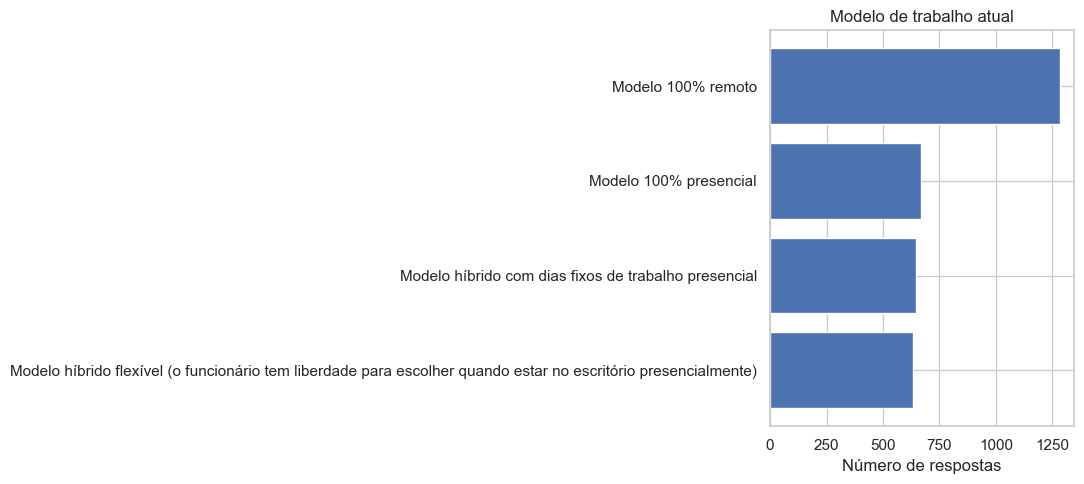

,categoria,quantidade,percentual_das_respostas_preenchidas
0,Modelo híbrido flexível (o funcionário tem lib...,1387,42.97
1,Modelo 100% remoto,1360,42.13
2,Modelo híbrido com dias fixos de trabalho pres...,421,13.04
3,Modelo 100% presencial,60,1.86


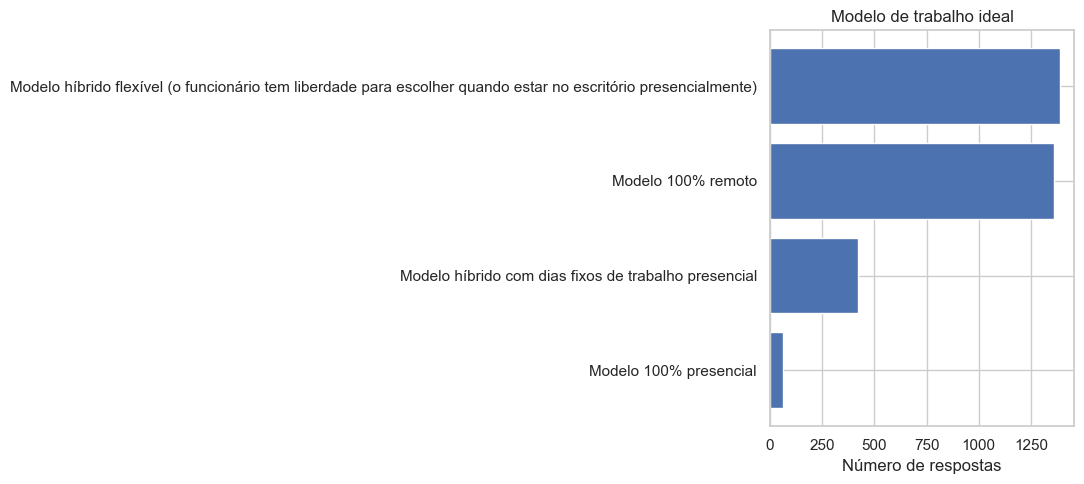

Percentual do modelo ideal dentro de cada categoria de modelo atual:


2.r_modelo_de_trabalho_ideal,Modelo 100% presencial,Modelo 100% remoto,Modelo híbrido com dias fixos de trabalho presencial,Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)
2.q_modelo_de_trabalho_atual,,,,
Modelo 100% presencial,6.1,17.2,33.4,43.3
Modelo 100% remoto,0.5,73.1,2.0,24.4
Modelo híbrido com dias fixos de trabalho presencial,1.1,23.9,23.6,51.5
Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente),0.8,24.4,3.2,71.6


In [8]:
coluna_modelo_atual = "2.q_modelo_de_trabalho_atual"
coluna_modelo_ideal = "2.r_modelo_de_trabalho_ideal"

for coluna, titulo in [
    (coluna_modelo_atual, "Modelo de trabalho atual"),
    (coluna_modelo_ideal, "Modelo de trabalho ideal"),
]:
    if coluna in df.columns:
        mostrar_frequencias(coluna, titulo)
    else:
        print(f"Coluna não encontrada: {coluna}")

if coluna_modelo_atual in df.columns and coluna_modelo_ideal in df.columns:
    comparacao_modelo = df[[coluna_modelo_atual, coluna_modelo_ideal]].dropna()
    if not comparacao_modelo.empty:
        tabela_modelos = pd.crosstab(
            comparacao_modelo[coluna_modelo_atual],
            comparacao_modelo[coluna_modelo_ideal],
            normalize="index"
        ) * 100
        print("Percentual do modelo ideal dentro de cada categoria de modelo atual:")
        display(tabela_modelos.round(1))

## 9. Linguagens de programação preferidas

Algumas perguntas da pesquisa podem estar representadas por colunas de seleção múltipla, com valores como 1 para opção marcada e 0 para opção não marcada. Vamos verificar as colunas disponíveis antes de contar as marcações.

A análise abaixo considera as colunas que começam com `4.c.` e que representam linguagens preferidas. O resultado deve ser interpretado conforme a estrutura real dessas respostas.

,linguagem,marcacoes
2,Python,1929
0,SQL,1764
1,R,328
6,Scala,70
3,C/C++/C#,49
8,Rust,35
4,Julia,18
7,DAX,8
5,Visual Basic/VBA,1
9,Não utilizo nenhuma das linguagens listadas,0


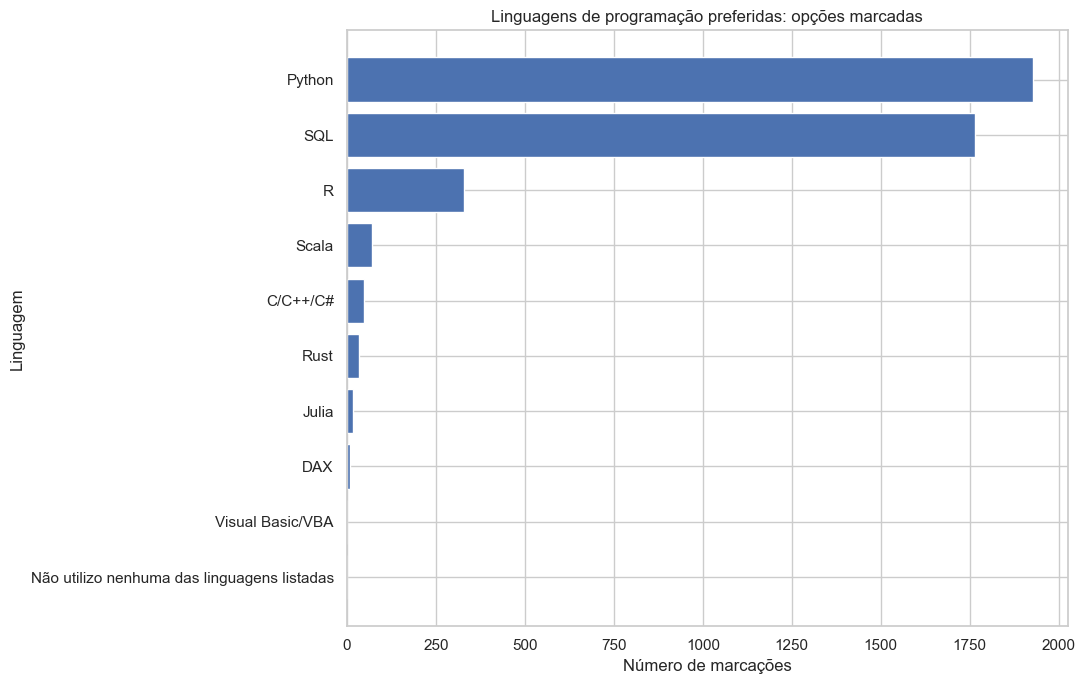

In [9]:
colunas_linguagens = [
    coluna for coluna in df.columns
    if coluna.startswith("4.c.") and coluna != "4.c_linguagem_preferida"
]

if colunas_linguagens:
    contagens_linguagens = {}

    for coluna in colunas_linguagens:
        # Converte os valores para números; valores que não forem numéricos ficam ausentes.
        valores = pd.to_numeric(df[coluna], errors="coerce")
        contagens_linguagens[coluna.split(".", 2)[-1].split("_", 1)[-1]] = int((valores == 1).sum())

    tabela_linguagens = (
        pd.DataFrame(list(contagens_linguagens.items()), columns=["linguagem", "marcacoes"])
        .sort_values("marcacoes", ascending=False)
    )
    display(tabela_linguagens)

    dados_grafico_linguagens = tabela_linguagens.head(15).sort_values("marcacoes")
    plt.figure(figsize=(11, 7))
    plt.barh(dados_grafico_linguagens["linguagem"], dados_grafico_linguagens["marcacoes"])
    plt.title("Linguagens de programação preferidas: opções marcadas")
    plt.xlabel("Número de marcações")
    plt.ylabel("Linguagem")
    plt.tight_layout()
    plt.show()
else:
    print("Não foram encontradas colunas de linguagens com o prefixo esperado. Revise os nomes na seção 2.")

## 10. Uso de inteligência artificial generativa no trabalho

Vamos observar as respostas sobre uso de ferramentas de inteligência artificial para produtividade. A análise utiliza a pergunta geral e, se disponível, mostra as categorias de uso separadamente.

,categoria,quantidade,percentual_das_respostas_preenchidas
0,Utilizo soluções pagas de AI Generativa (como ...,468,22.22
1,Utilizo apenas soluções gratuitas (como por ex...,460,21.84
2,Utilizo soluções pagas de AI Generativa (como ...,349,16.57
3,Utilizo soluções pagas de AI Generativa (como ...,224,10.64
4,Utilizo soluções de AI para código (exemplo: G...,122,5.79
5,Utilizo soluções pagas de AI Generativa (como ...,77,3.66
6,Utilizo apenas soluções gratuitas (como por ex...,75,3.56
7,Utilizo soluções pagas de AI Generativa (como ...,74,3.51
8,Utilizo soluções de AI para código (exemplo: G...,60,2.85
9,Utilizo soluções de AI para código (exemplo: G...,41,1.95


C:\Users\thiag\AppData\Local\Temp\ipykernel_2728\204074538.py:36: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


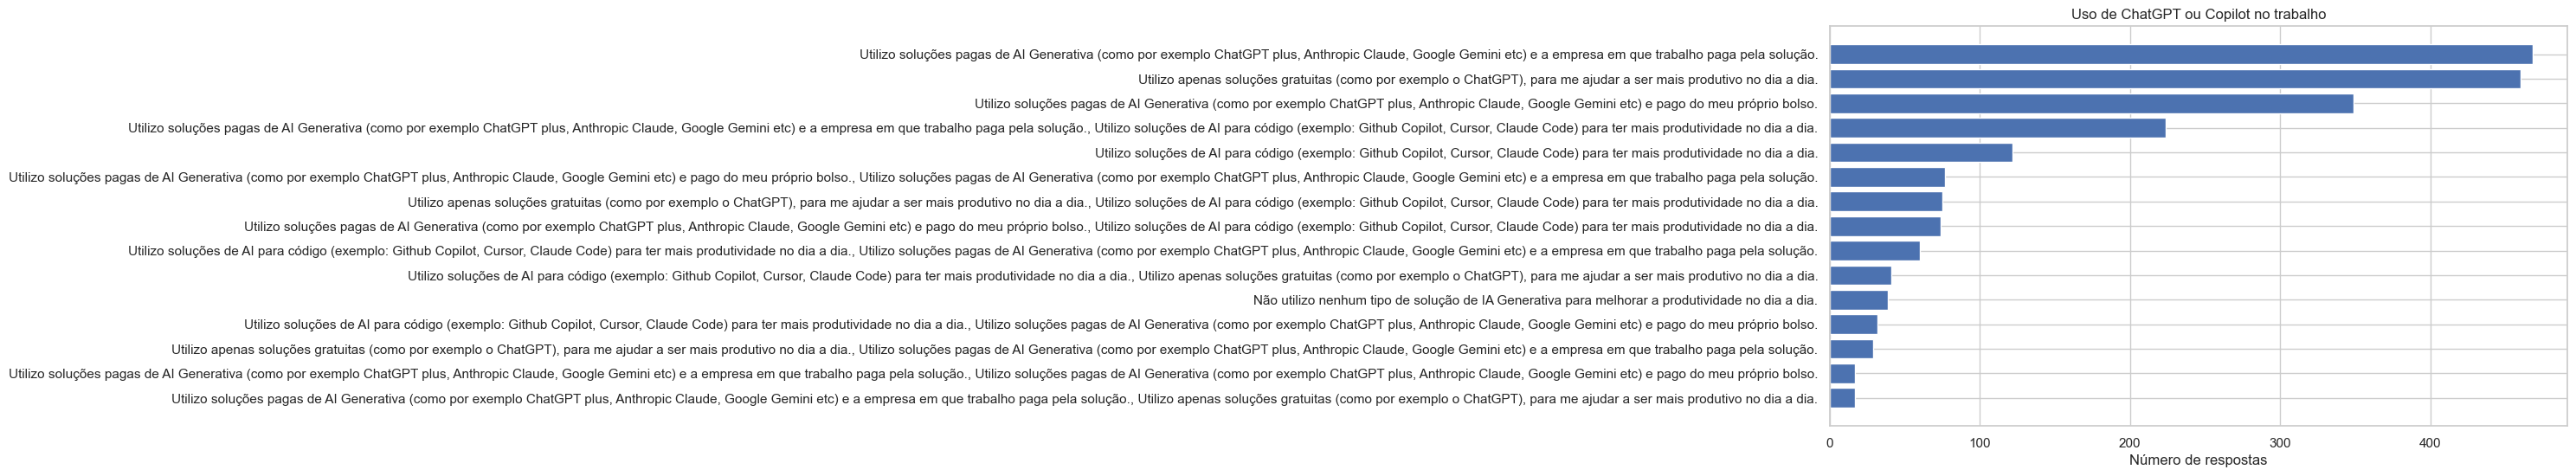

,tipo_de_uso,marcacoes
3,4.j.4 A empresa que trabalho paga pelas soluçõ...,892
1,4.j.2 Uso soluções gratuitas de AI Generativa ...,643
4,4.j.5 Uso soluções do tipo Copilot,628
2,4.j.3 Uso e pago pelas soluções de AI Generati...,567
0,4.j.1 Não uso soluções de AI Generativa com fo...,44


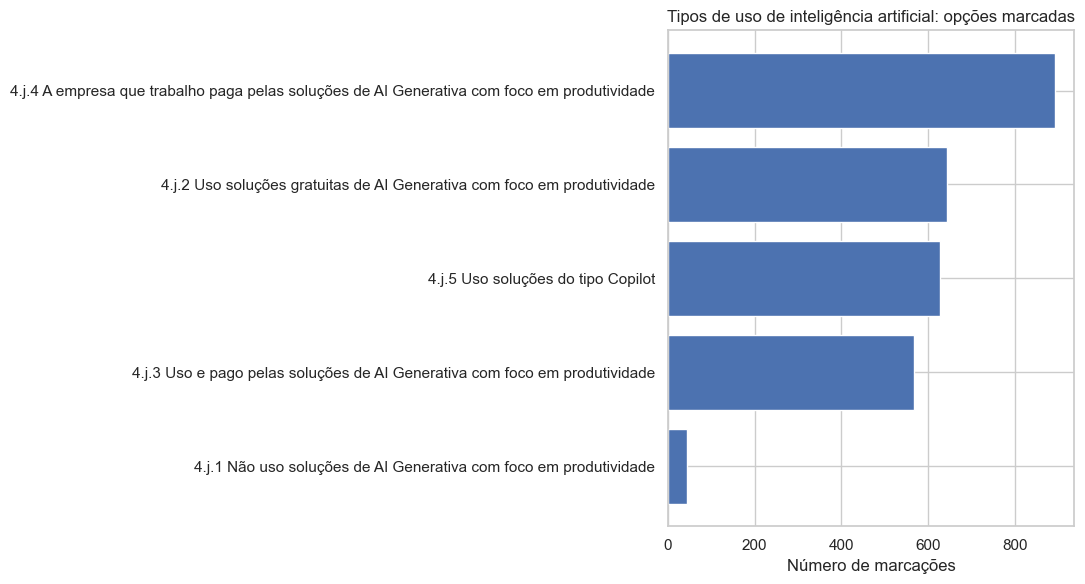

In [10]:
coluna_uso_ia = "4.j_usa_chatgpt_ou_copilot_no_trabalho?"

if coluna_uso_ia in df.columns:
    mostrar_frequencias(coluna_uso_ia, "Uso de ChatGPT ou Copilot no trabalho")
else:
    print(f"Coluna não encontrada: {coluna_uso_ia}")

# Verifica se existem colunas de seleção múltipla associadas à pergunta de uso de IA.
colunas_ia = [
    coluna for coluna in df.columns
    if coluna.startswith("4.j.") and coluna != coluna_uso_ia
]

if colunas_ia:
    contagens_ia = {}
    for coluna in colunas_ia:
        valores = pd.to_numeric(df[coluna], errors="coerce")
        contagens_ia[coluna.split("_", 1)[-1]] = int((valores == 1).sum())

    tabela_ia = (
        pd.DataFrame(list(contagens_ia.items()), columns=["tipo_de_uso", "marcacoes"])
        .sort_values("marcacoes", ascending=False)
    )
    display(tabela_ia)

    dados_grafico_ia = tabela_ia.sort_values("marcacoes")
    plt.figure(figsize=(11, 6))
    plt.barh(dados_grafico_ia["tipo_de_uso"], dados_grafico_ia["marcacoes"])
    plt.title("Tipos de uso de inteligência artificial: opções marcadas")
    plt.xlabel("Número de marcações")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()
else:
    print("Não foram encontradas colunas de seleção múltipla para essa pergunta.")

## 11. Resumo dos principais indicadores

Esta seção reúne alguns números básicos para facilitar a consulta. Eles descrevem o arquivo e as respostas disponíveis, não todo o mercado brasileiro.

In [11]:
indicadores = {
    "Total de linhas no arquivo": len(df),
    "Total de colunas no arquivo": df.shape[1],
    "Linhas totalmente duplicadas": int(df.duplicated().sum()),
    "Percentual médio de células ausentes": round(float(df.isna().mean().mean() * 100), 2),
}

if "2.h_faixa_salarial" in df.columns:
    indicadores["Respostas preenchidas sobre faixa salarial"] = int(df["2.h_faixa_salarial"].notna().sum())

if "2.g_nivel" in df.columns:
    indicadores["Respostas preenchidas sobre nível profissional"] = int(df["2.g_nivel"].notna().sum())

display(pd.DataFrame(list(indicadores.items()), columns=["indicador", "valor"]))

,indicador,valor
0,Total de linhas no arquivo,3495.00
1,Total de colunas no arquivo,388.00
2,Linhas totalmente duplicadas,1.00
3,Percentual médio de células ausentes,61.94
4,Respostas preenchidas sobre faixa salarial,3228.00
5,Respostas preenchidas sobre nível profissional,2501.00


### Conclusões

Objetivo

Este projeto explorou as respostas da pesquisa State of Data 2025–2026 para conhecer o perfil dos participantes e investigar experiência profissional, remuneração, modelos de trabalho, linguagens de programação e uso de inteligência artificial. A análise foi realizada com Python, Pandas, NumPy, Matplotlib e Seaborn.

Perfil dos participantes

O arquivo contém 3.495 registros e 388 colunas. A faixa etária mais frequente foi de 30 a 34 anos, com 27,5% das respostas. Em seguida aparecem 25 a 29 anos, com 23,9%, e 35 a 39 anos, com 18,6%.

Sobre gênero, 77,5% das respostas foram de participantes que informaram ser homens e 22,0% de participantes que informaram ser mulheres. As demais respostas foram “Prefiro não informar” e “Outro”. Na pergunta sobre região de residência, 3.370 pessoas responderam: 64,4% indicaram o Sudeste e 16,0% o Sul. Na formação acadêmica, a categoria mais frequente foi pós-graduação, com 40,2%, seguida de graduação/bacharelado, com 30,6%.

Esses resultados descrevem os participantes da pesquisa. A concentração em algumas regiões e categorias precisa ser considerada antes de generalizar os resultados para todo o mercado brasileiro.

Experiência profissional e remuneração

Na pergunta sobre tempo de experiência em dados, 3.228 respostas estavam preenchidas. A faixa mais frequente foi de 3 a 4 anos, com 25,2%, seguida de 5 a 6 anos, com 20,1%.

Para comparar remuneração e nível profissional, foram consideradas 2.501 respostas com as duas informações preenchidas. Entre os participantes juniores, a faixa salarial mais frequente foi de R$ 4.001 a R$ 6.000 por mês, com 23,6%. Entre os plenos, a faixa de R$ 8.001 a R$ 12.000 foi a mais frequente, com 32,7%. Entre os seniores, essa mesma faixa representou 32,4%. No grupo Especialista/Staff+, a faixa mais frequente foi de R$ 12.001 a R$ 16.000, com 26,1%.

As faixas salariais foram comparadas por distribuição percentual. Não foi calculada uma média exata, pois os valores estão agrupados em intervalos. As diferenças observadas não provam que o nível profissional, isoladamente, cause diferenças salariais.

Modelos de trabalho

Na pergunta sobre modelo atual, 3.228 pessoas responderam. O trabalho 100% remoto foi a categoria mais frequente, com 39,7%, seguido do trabalho 100% presencial, com 20,8%, do híbrido com dias fixos, com 20,0%, e do híbrido flexível, com 19,5%.

No modelo ideal, o híbrido flexível foi a opção mais frequente, com 43,0%, seguido do modelo 100% remoto, com 42,1%. O trabalho 100% presencial foi indicado por 1,9% das respostas.

A comparação sugere preferência dos respondentes por modelos de trabalho flexíveis. Isso não significa que todas as empresas ofereçam essas modalidades ou que todos os profissionais tenham a mesma preferência.

Linguagens de programação

Na pergunta sobre linguagem preferida, 2.096 respostas estavam preenchidas. A combinação “Python, SQL” apareceu em 35,1% das respostas e “SQL, Python” em 24,1%; a resposta “Python” apareceu em 12,1%.

Nas colunas de seleção das linguagens, Python foi marcado por 1.929 respondentes, equivalente a 92,0% das 2.096 respostas válidas, e SQL por 1.764, equivalente a 84,2%. Como era possível marcar mais de uma opção, esses percentuais não devem ser somados.

Os dados mostram presença expressiva de Python e SQL entre as preferências declaradas. Eles não constituem, por si só, uma classificação de todas as tecnologias exigidas pelas empresas.

Uso de inteligência artificial

A pergunta geral sobre uso de IA tinha 2.106 respostas preenchidas. Como as opções podiam ser combinadas, analisamos as colunas de seleção separadamente. Entre as respostas válidas, 42,4% marcaram que a empresa paga pelas ferramentas de IA generativa, 30,5% marcaram uso de soluções gratuitas, 26,9% marcaram soluções pagas pelo próprio profissional e 29,8% marcaram uso de ferramentas de assistência à programação, como Copilot.

Como havia possibilidade de selecionar mais de uma alternativa, as categorias não são grupos exclusivos e os percentuais não devem ser somados. Esses dados descrevem formas de uso informadas pelos respondentes, mas não provam que a IA aumente a produtividade.

Principais aprendizados

O projeto permitiu praticar leitura de arquivos CSV, inspeção de dados, avaliação de valores ausentes, cálculo de frequências e percentuais, cruzamento de variáveis e construção de gráficos. Também mostrou a importância de conferir o formato das respostas antes de calcular indicadores e de interpretar cada resultado dentro de seu contexto.

Limitações

- A pesquisa pode não representar todos os profissionais de dados do Brasil.
- O número de respostas válidas muda de uma pergunta para outra.
- Algumas perguntas permitem múltiplas respostas.
- As faixas salariais não permitem calcular uma média exata sem hipóteses adicionais.
- Diferenças entre grupos não demonstram causa e efeito.
- Os resultados dependem da forma como as perguntas foram formuladas e respondidas.

Conclusão final

A análise encontrou padrões nas respostas relacionadas ao perfil dos participantes, à experiência, à remuneração, aos modelos de trabalho, às linguagens de programação e ao uso de inteligência artificial. Entre os destaques estão a concentração de respostas nas faixas etárias de 25 a 39 anos, diferenças na distribuição salarial entre níveis profissionais, preferência declarada por modelos flexíveis e presença expressiva de Python e SQL.

O principal aprendizado é que Ciência de Dados não se resume a escrever código ou montar gráficos. É necessário formular perguntas, verificar a qualidade das informações, escolher análises adequadas, interpretar os resultados e reconhecer as limitações dos dados.